# Evaluación del sistema de reconocimiento facial

Calcula las métricas, matrices de confusión y gráficos del capítulo 4 del informe.

- **Parte 1 — Evaluar los embeddings:** ¿los vectores de 128 dimensiones separan bien a las personas? Cada rostro se predice con su vecino más cercano (k-NN, k = 1) con validación cruzada.
- **Parte 2 — Evaluar el reconocimiento:** con los criterios de `recognize_faces_*.py` (Cuadro 2), ¿el sistema acierta?

Las distancias se calculan con `face_recognition.face_distance`, la misma función que usan los scripts de reconocimiento.

## 1. Librerías

In [98]:
from pathlib import Path

import cv2
import face_recognition
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier

### Colores

Los mismos de `evaluar.py`.

In [99]:
TEXTO = "#0b0b0b"         # texto principal
TEXTO_2 = "#52514e"       # ejes y etiquetas
GRILLA = "#e4e3df"        # lineas de grilla y bordes
AZULES = ["#fcfcfb", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95"]  # claro -> oscuro
COLOR_SERIE = {"precision": "#2a78d6", "recall": "#eb6834", "f1-score": "#1baf7a"}

plt.rcParams.update({
    "text.color": TEXTO,
    "axes.labelcolor": TEXTO_2,
    "xtick.color": TEXTO_2,
    "ytick.color": TEXTO_2,
    "axes.edgecolor": GRILLA,
})

## 2. Parámetros de los embeddings

Los mismos de `encode_faces.py`, usados en el informe.

| Parámetro | Valor | Efecto |
|---|---|---|
| `DATASET` | `dataset` | fotos de entrada, una subcarpeta por persona |
| `DETECTOR` | `hog` | detector de rostros |
| `NUM_JITTERS` | `1` | número de variaciones del recorte que se promedian |
| `MODELO` | `small` | 5 puntos faciales para alinear la cara |

In [100]:
DATASET = "dataset"
DETECTOR = "hog"
NUM_JITTERS = 1
MODELO = "small"

### 2.1 Generar los embeddings

Igual que `encode_faces.py`: se recorren las carpetas y fotos en orden alfabético y se obtiene un vector de 128 dimensiones por cada rostro detectado.

In [101]:
EXTENSIONES = {".jpg", ".jpeg", ".png"}

encodings, nombres = [], []
for carpeta in sorted(p for p in Path(DATASET).iterdir() if p.is_dir()):
    for foto in sorted(f for f in carpeta.iterdir() if f.suffix.lower() in EXTENSIONES):
        imagen = cv2.imread(str(foto))
        if imagen is None:
            continue
        rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)
        cajas = face_recognition.face_locations(rgb, model=DETECTOR)
        for encoding in face_recognition.face_encodings(
                rgb, cajas, num_jitters=NUM_JITTERS, model=MODELO):
            encodings.append(encoding)
            nombres.append(carpeta.name)

X, y = np.array(encodings), np.array(nombres)
etiquetas = sorted(set(y))
NOMBRE_CONFIG = f"{DETECTOR}, jitters={NUM_JITTERS}, {MODELO}"
print(f"{NOMBRE_CONFIG}: {len(y)} rostros, {len(etiquetas)} personas")

hog, jitters=1, small: 270 rostros, 8 personas


---
# Parte 1 -Evaluar los embeddings

Pregunta: **¿los vectores de una misma persona quedan cerca entre sí y lejos de los de otras?**

Se usa la regla más simple (el vecino más cercano, sin umbrales) para que el resultado dependa solo de los embeddings.

## 3. Vecino más cercano con validación cruzada

`KNeighborsClassifier(n_neighbors=1)` predice cada rostro con la persona de su vecino más cercano (distancia euclidiana). No se entrena ninguna red: el clasificador solo guarda los vectores para compararlos.

`cross_val_predict` divide los rostros en 5 partes estratificadas: compara cada parte con las otras 4, de modo que ningún rostro se compara consigo mismo. La semilla fija hace que el resultado se repita.

In [102]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y_pred = cross_val_predict(KNeighborsClassifier(n_neighbors=1), X, y, cv=cv)

print(classification_report(y, y_pred, zero_division=0, digits=3))

                precision    recall  f1-score   support

  Karla_Abarca      1.000     1.000     1.000        40
   Marco_Guapi      0.980     0.980     0.980        51
    alan_grant      1.000     1.000     1.000        12
claire_dearing      0.957     0.978     0.968        46
 ellie_sattler      0.967     1.000     0.983        29
   ian_malcolm      1.000     0.974     0.987        39
  john_hammond      0.944     0.944     0.944        18
    owen_grady      1.000     0.971     0.986        35

      accuracy                          0.981       270
     macro avg      0.981     0.981     0.981       270
  weighted avg      0.982     0.981     0.982       270



## 4. Matriz de confusión

Filas = persona real, columnas = predicha. Lo que queda fuera de la diagonal son los errores.

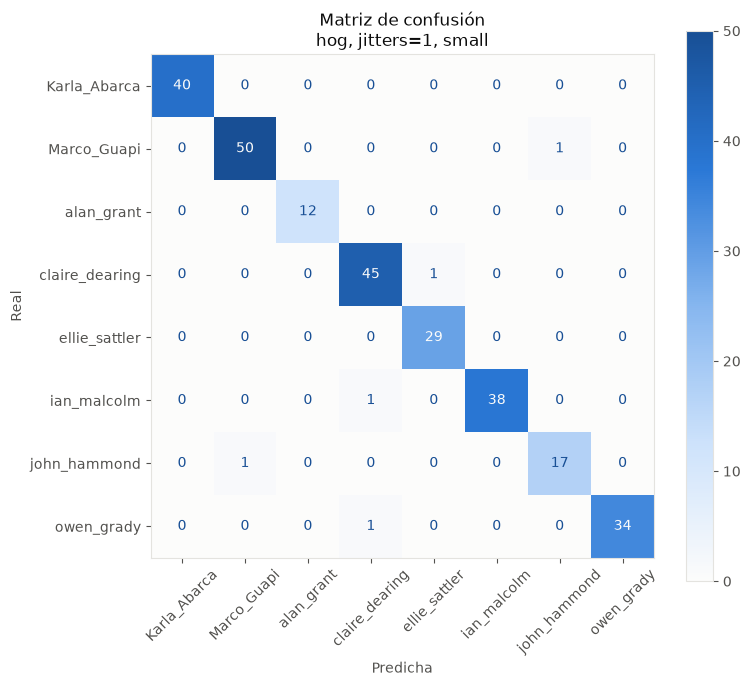

In [103]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    y, y_pred, labels=etiquetas, ax=ax, xticks_rotation=45,
    cmap=LinearSegmentedColormap.from_list("azules", AZULES),
)
ax.set_title(f"Matriz de confusión\n{NOMBRE_CONFIG}")
ax.set_xlabel("Predicha")
ax.set_ylabel("Real")
plt.tight_layout()
plt.show()

---
# Parte 2-Evaluar el reconocimiento

Pregunta: **con estos embeddings y las reglas de decisión de `recognize_faces_*.py`, ¿el sistema acierta?**

Misma lógica que los scripts de reconocimiento:
1. Para cada persona se promedian las `NEAREST` distancias más cercanas.
2. Gana la persona con el promedio más bajo.
3. Solo se acepta si ese promedio es `<= THRESHOLD` **y** le gana a la segunda persona por al menos `MIN_MARGIN`. Si no, el rostro queda como **Desconocido**.

Esta regla no existe en scikit-learn, por eso se programa aquí. Cada rostro se compara contra todos los demás, nunca contra sí mismo (*leave-one-out*).

## 5. Parámetros de reconocimiento

Los mismos valores de `recognize_faces_image.py` (Cuadro 2 del informe).

In [104]:
THRESHOLD = 0.48    # distancia promedio maxima para aceptar a alguien
NEAREST = 3         # cuantos vecinos mas cercanos se promedian por persona
MIN_MARGIN = 0.055  # ventaja minima sobre la segunda persona
DESCONOCIDO = "Desconocido"

## 6. Reconocer cada rostro

`D` guarda la distancia de cada rostro a todos los demás, con la misma función que usa `recognize_faces_image.py`. La diagonal (cada rostro contra sí mismo, distancia cero) se pone en infinito para que nadie se reconozca a sí mismo.

In [105]:
D = np.array([face_recognition.face_distance(X, encoding) for encoding in X])
np.fill_diagonal(D, np.inf)

indices = {persona: np.flatnonzero(y == persona) for persona in etiquetas}


def puntajes(distancias):
    """Promedio de las NEAREST distancias mas cercanas de cada persona."""
    scores = {}
    for persona in etiquetas:
        d = np.sort(distancias[indices[persona]])
        d = d[np.isfinite(d)]          # quita la distancia del rostro consigo mismo
        scores[persona] = d[:NEAREST].mean()
    return scores


def reconocer(distancias):
    """Devuelve (nombre, mejor_distancia, margen) con la regla de los scripts."""
    scores = puntajes(distancias)
    ranking = sorted(scores, key=scores.get)
    mejor, segunda = scores[ranking[0]], scores[ranking[1]]
    aceptado = mejor <= THRESHOLD and (segunda - mejor) >= MIN_MARGIN
    return (ranking[0] if aceptado else DESCONOCIDO), mejor, segunda - mejor


resultados = pd.DataFrame(
    [reconocer(D[i]) for i in range(len(y))],
    columns=["prediccion", "distancia", "margen"],
)
resultados.insert(0, "real", y)
y_rec = resultados["prediccion"].to_numpy()

aciertos = (y_rec == y).sum()
desconocidos = (y_rec == DESCONOCIDO).sum()
errores = len(y) - aciertos - desconocidos
print(f"aciertos:     {aciertos:4d}  ({aciertos / len(y):.1%})")
print(f"desconocidos: {desconocidos:4d}  ({desconocidos / len(y):.1%})")
print(f"confusiones:  {errores:4d}  ({errores / len(y):.1%})  <- reconocido como otra persona")

aciertos:      242  (89.6%)
desconocidos:   28  (10.4%)
confusiones:     0  (0.0%)  <- reconocido como otra persona


## 7. Precision / recall / F1 del reconocimiento

Un rostro que queda como *Desconocido* baja el **recall** de su persona, pero no la **precision** de nadie: el sistema no se equivocó de persona, solo no se atrevió a decidir.

En lugar de `accuracy` aparece `micro avg`: como *Desconocido* no es una persona del dataset, scikit-learn lo reporta así. Su `recall` es la proporción de rostros reconocidos correctamente.

In [106]:
print(classification_report(y, y_rec, labels=etiquetas, zero_division=0, digits=3))

                precision    recall  f1-score   support

  Karla_Abarca      1.000     0.750     0.857        40
   Marco_Guapi      1.000     0.961     0.980        51
    alan_grant      1.000     0.500     0.667        12
claire_dearing      1.000     0.935     0.966        46
 ellie_sattler      1.000     0.931     0.964        29
   ian_malcolm      1.000     0.949     0.974        39
  john_hammond      1.000     0.889     0.941        18
    owen_grady      1.000     0.971     0.986        35

     micro avg      1.000     0.896     0.945       270
     macro avg      1.000     0.861     0.917       270
  weighted avg      1.000     0.896     0.941       270



## 8. Matriz de confusión del reconocimiento

Igual que la de la Parte 1, con una columna extra para los *Desconocido*.

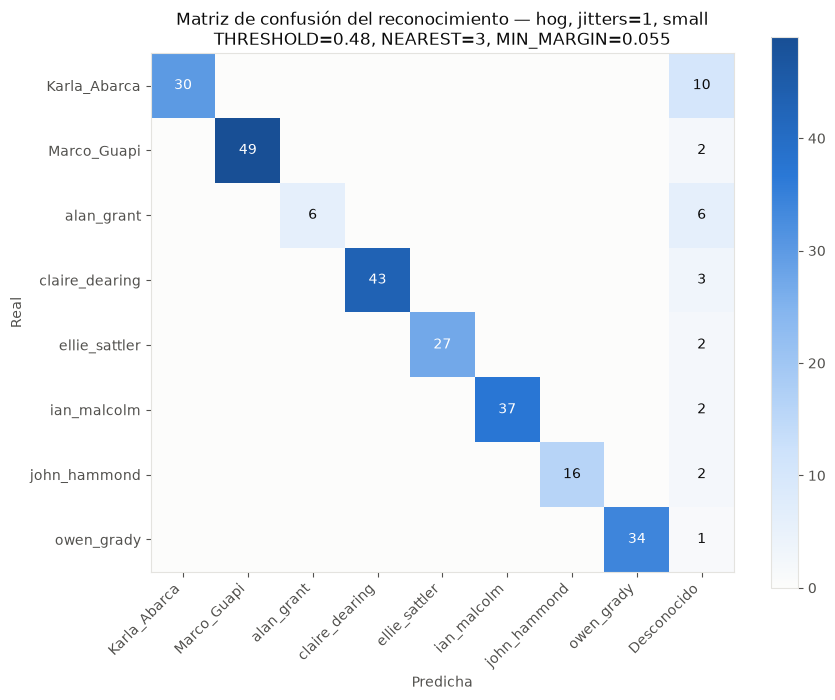

In [107]:
columnas_rec = etiquetas + [DESCONOCIDO]
cm_rec = confusion_matrix(y, y_rec, labels=columnas_rec)[:len(etiquetas)]

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(cm_rec, cmap=LinearSegmentedColormap.from_list("azules", AZULES), vmin=0)
fig.colorbar(im, ax=ax)

ax.set_xticks(range(len(columnas_rec)), columnas_rec, rotation=45, ha="right")
ax.set_yticks(range(len(etiquetas)), etiquetas)
ax.set_xlabel("Predicha")
ax.set_ylabel("Real")
ax.set_title(f"Matriz de confusión del reconocimiento — {NOMBRE_CONFIG}\nTHRESHOLD={THRESHOLD}, NEAREST={NEAREST}, MIN_MARGIN={MIN_MARGIN}")

umbral = cm_rec.max() * 0.55
for i in range(cm_rec.shape[0]):
    for j in range(cm_rec.shape[1]):
        if cm_rec[i, j]:
            color = "white" if cm_rec[i, j] > umbral else TEXTO
            ax.text(j, i, cm_rec[i, j], ha="center", va="center", color=color)

plt.tight_layout()
plt.show()

## 9. Cómo cambia el resultado según `THRESHOLD`

Recorre varios umbrales (dejando `NEAREST` y `MIN_MARGIN` fijos) y muestra qué parte de los rostros queda como acierto, desconocido o confusión. Sirve para elegir el umbral: más bajo da menos confusiones pero más desconocidos.

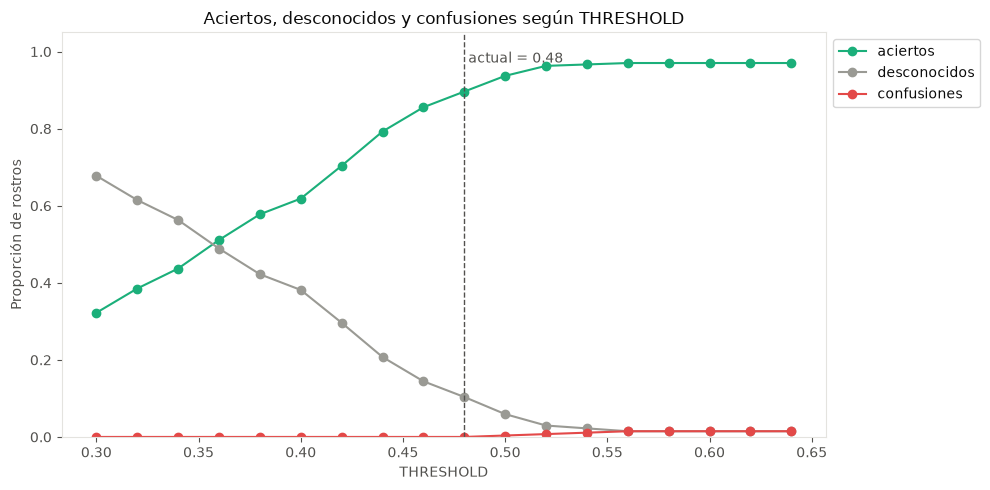

,aciertos,desconocidos,confusiones
THRESHOLD,,,
0.30,0.322,0.678,0.000
0.32,0.385,0.615,0.000
0.34,0.437,0.563,0.000
0.36,0.511,0.489,0.000
0.38,0.578,0.422,0.000
0.40,0.619,0.381,0.000
0.42,0.704,0.296,0.000
0.44,0.793,0.207,0.000
0.46,0.856,0.144,0.000


In [108]:
umbral_original = THRESHOLD
barrido = []
for THRESHOLD in np.round(np.arange(0.30, 0.66, 0.02), 2):
    pred = np.array([reconocer(D[i])[0] for i in range(len(y))])
    barrido.append({
        "THRESHOLD": THRESHOLD,
        "aciertos": (pred == y).mean(),
        "desconocidos": (pred == DESCONOCIDO).mean(),
        "confusiones": ((pred != y) & (pred != DESCONOCIDO)).mean(),
    })
THRESHOLD = umbral_original
barrido = pd.DataFrame(barrido).set_index("THRESHOLD")

ax = barrido.plot(
    figsize=(10, 5), marker="o", ylim=(0, 1.05),
    color=[COLOR_SERIE["f1-score"], "#9a9a94", "#e34948"],
    title="Aciertos, desconocidos y confusiones según THRESHOLD",
)
ax.axvline(THRESHOLD, color=TEXTO_2, linestyle="--", linewidth=1)
ax.text(THRESHOLD, 1.0, f" actual = {THRESHOLD}", color=TEXTO_2, va="top")
ax.set_ylabel("Proporción de rostros")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

barrido.round(3)

## 10. Comparar métricas por persona

Une las dos partes en un solo gráfico: para cada persona, el **F1 de los embeddings** (Parte 1, validación cruzada) frente al **recall** y el **F1 del reconocimiento** (Parte 2, con los umbrales).

La distancia entre la barra azul y las otras dos es lo que cuestan los umbrales: rostros que los embeddings sí separan bien pero que el sistema deja como *Desconocido*.

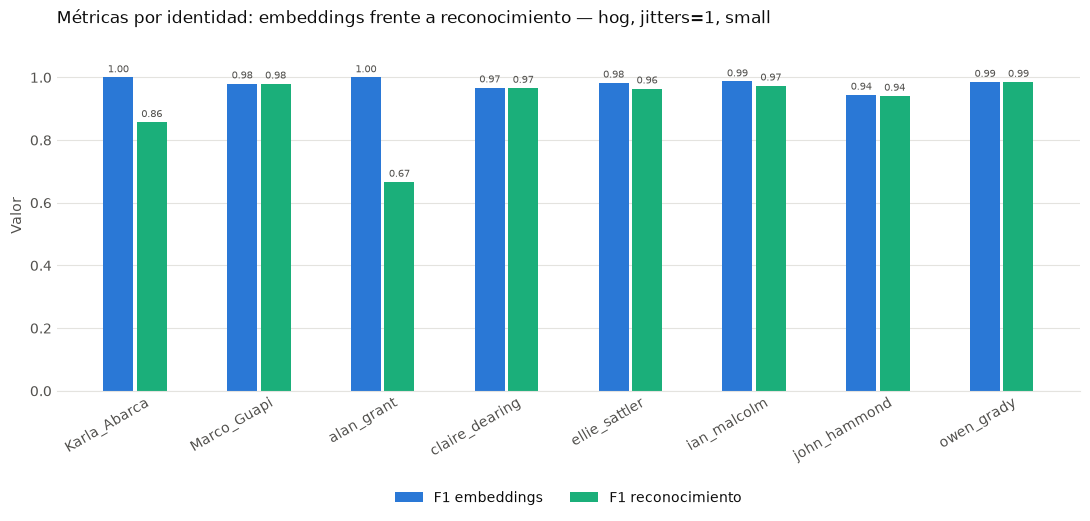

In [109]:
reporte_p1 = classification_report(y, y_pred, labels=etiquetas, zero_division=0, output_dict=True)
reporte_p2 = classification_report(y, y_rec, labels=etiquetas, zero_division=0, output_dict=True)

series = {
    "F1 embeddings": ([reporte_p1[p]["f1-score"] for p in etiquetas], COLOR_SERIE["precision"]),
    # "Recall reconocimiento": ([reporte_p2[p]["recall"] for p in etiquetas], COLOR_SERIE["recall"]),
    "F1 reconocimiento": ([reporte_p2[p]["f1-score"] for p in etiquetas], COLOR_SERIE["f1-score"]),
}

fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(etiquetas))
ancho = 0.27
for k, (nombre, (valores, color)) in enumerate(series.items()):
    barras = ax.bar(x + (k - 1) * ancho, valores, ancho * 0.9, label=nombre, color=color, zorder=2)
    ax.bar_label(barras, fmt="%.2f", fontsize=7, padding=2, color=TEXTO_2)

ax.set_xticks(x, etiquetas, rotation=30, ha="right")
ax.set_ylim(0, 1.12)
ax.set_ylabel("Valor")
ax.yaxis.grid(True, color=GRILLA, linewidth=0.8, zorder=0)
ax.tick_params(length=0)
for borde in ("top", "right", "left"):
    ax.spines[borde].set_visible(False)

ax.set_title(f"Métricas por identidad: embeddings frente a reconocimiento — {NOMBRE_CONFIG}", loc="left", pad=12)
# leyenda debajo del grafico para que no tape el titulo
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.25))
plt.tight_layout()
plt.show()